# Objective 3 — Extending misstatement prediction to recent periods with SEC XBRL data

**Objective.** Extend the established framework to recent reporting periods by integrating the SEC Financial Statement Data Sets (FSDS, XBRL-based) with publicly documented enforcement (AAERs), and assess whether the extension is valid.

**Steps.**
1. Inventory and extract the FSDS quarters (2009 Q2 – 2026 Q3) — original 10-K values **as first reported**.
2. Build a firm-year panel mapped to the Bao et al. Compustat items; measure coverage and mapping fidelity against Compustat.
3. Construct two public outcome labels: AAER firm-years (CIK-linked) and an **XBRL-derived restatement label** (a later 10-K/A that changes net income, total assets or equity), with the date each label became public.
4. Transfer test: Compustat-trained models scored on XBRL inputs (AAER labels, 2011–2014).
5. XBRL-native rolling models on restatement labels, 2013–2024, using only labels public before each test year.
6. Distribution shift (PSI) between Compustat and XBRL inputs and over time.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from misstatement.config import *
from misstatement import data, metrics, models, plots
plots.style()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 3)
from misstatement import fsds
from sklearn.metrics import roc_auc_score

## 1. FSDS inventory and extraction

In [2]:
FSDS_ROOT = DATA_RAW                 # folder holding SEC_Financial_Statements_* and 2026q3 sub-folders
INTERIM = DATA_INTERIM / 'fsds'
raw_present = any(pathlib.Path(FSDS_ROOT).glob('**/num*.txt'))
if raw_present:                       # full extraction (about 1-2 hours on a laptop for 70 quarters)
    inv = fsds.extract_all(FSDS_ROOT, INTERIM)
    inv.to_csv(TABLES / 'T12_fsds_quarter_inventory.csv', index=False)
else:                                 # use the inventory and interim files produced on the original machine
    inv = pd.read_csv(TABLES / 'T12_fsds_quarter_inventory.csv')
print(inv.status.value_counts().to_string())
inv[inv.status != 'ok']

status
ok                    70
duplicate download     3
empty sub file         1


,sub,num,quarter,n_sub,status
6,SEC_Financial_Statements_2009/sub.txt,NaN,NaN,NaN,empty sub file
22,SEC_Financial_Statements_2013/sub (5).txt,NaN,2013Q4,NaN,duplicate download
69,SEC_Financial_Statements_2025(1)/sub (3).txt,NaN,2025Q4,NaN,duplicate download
72,SEC_Financial_Statements_2025(1)/sub (6).txt,NaN,2025Q2,NaN,duplicate download


In [3]:
if any(INTERIM.glob('*_num.parquet')):
    sub, num = fsds.load_interim(INTERIM)
    print(f'{len(sub):,} 10-K / 10-K/A filings, {len(num):,} extracted values')
    P = fsds.build_panel(sub, num)
    R = fsds.restatement_labels(sub, num)
    P = P[P.fyear.between(2009, 2025)].copy()
    P.to_parquet(DATA_PROCESSED / 'xbrl_panel.parquet', compression='zstd'); R.to_parquet(DATA_PROCESSED / 'xbrl_restatements.parquet')
else:   # cloned repository without the raw FSDS: use the processed panel shipped with it
    P = pd.read_parquet(DATA_PROCESSED / 'xbrl_panel.parquet'); R = pd.read_parquet(DATA_PROCESSED / 'xbrl_restatements.parquet')
print(f'Panel: {len(P):,} firm-years, {P.cik.nunique():,} companies, fiscal {P.fyear.min()}-{P.fyear.max()}')
P.groupby('fyear').size().to_frame('firm_years').T

100,332 10-K / 10-K/A filings, 4,152,022 extracted values


Panel: 94,229 firm-years, 13,998 companies, fiscal 2009-2025


fyear,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
firm_years,444,1338,6744,6944,6905,6821,6429,6000,5905,5767,5597,5764,6504,6244,5813,5544,5466


## 2. Coverage and mapping fidelity against Compustat

In [4]:
cov = (P[data.RAW27].notna().mean() * 100).round(1).sort_values().to_frame('XBRL coverage %')
bao = data.load_bao(); aaer = data.load_aaer()
# Link GVKEY (Compustat) to CIK (SEC) through shared AAER numbers, keeping one-to-one links only
link = bao[bao.p_aaer.notna()][['gvkey', 'p_aaer']].drop_duplicates().merge(aaer[['p_aaer', 'cik']].drop_duplicates(), on='p_aaer')
link = link[['gvkey', 'cik']].drop_duplicates()
link = link[~link.gvkey.duplicated(keep=False) & ~link.cik.duplicated(keep=False)]
J = bao.merge(link, on='gvkey').merge(P, on=['cik', 'fyear'], suffixes=('_c', '_x'))
fid = []
for v in data.RAW27:
    a, b = J[f'{v}_c'], J[f'{v}_x'].fillna(0)
    both = (a.abs() > 0) & (b.abs() > 0)
    rel = ((a - b).abs() / a.abs())[both]
    fid.append(dict(item=v, label=data.LABELS[v], within_5pct=(rel <= 0.05).mean(), within_1pct=(rel <= 0.01).mean(),
                    spearman=a[both].corr(b[both], method='spearman'), n_both=int(both.sum())))
fid = pd.DataFrame(fid).set_index('item').join(cov).sort_values('within_5pct', ascending=False)
fid.to_csv(TABLES / 'T13_obj3_mapping_fidelity.csv')
print(f'Linked firm-years observed in both sources: {len(J)} ({J.cik.nunique()} companies)')
fid.round(3)

Linked firm-years observed in both sources: 526 (139 companies)


,label,within_5pct,within_1pct,spearman,n_both,XBRL coverage %
item,,,,,,
act,Current assets,0.992,0.977,1.000,520,76.6
lct,Current liabilities,0.990,0.983,0.999,521,76.6
at,Total assets,0.990,0.979,1.000,520,98.6
sale,Sales,0.990,0.955,0.999,488,71.8
ppegt,Gross PP&E,0.987,0.949,1.000,78,7.9
txp,Income taxes payable,0.987,0.967,1.000,151,16.5
lt,Total liabilities,0.971,0.921,0.999,520,97.7
txt,Income tax expense,0.970,0.968,0.985,495,69.1
csho,Shares outstanding,0.967,0.955,0.984,335,71.8


## 3. Outcome labels: AAERs and XBRL-derived restatements

In [5]:
P = P.merge(aaer[['cik', 'fyear', 'p_aaer']].drop_duplicates(['cik', 'fyear']), on=['cik', 'fyear'], how='left')
P['aaer'] = P.p_aaer.notna().astype(int)
P = P.merge(R[['cik', 'fyear', 'filed_a', 'days_to_amend']], on=['cik', 'fyear'], how='left')
P['restated'] = P.filed_a.notna().astype(int)
lab = P.groupby('fyear').agg(firm_years=('cik', 'size'), aaer=('aaer', 'sum'), restated=('restated', 'sum'),
                             restated_spac=('restated', lambda s: s[P.loc[s.index, 'spac'] == 1].sum()))
lab['restated_%'] = 100 * lab.restated / lab.firm_years
lab.to_csv(TABLES / 'T14_obj3_labels_by_year.csv'); display(lab.T)
print('Days from original 10-K to restating 10-K/A:', R.days_to_amend.describe()[['25%', '50%', '75%']].to_dict())
# Do AAER firm-years also show up as restatements? (convergent validity of the proxy)
x = P[P.fyear.between(2011, 2014)]
print(f"Restatement rate 2011-14: AAER firm-years {x[x.aaer == 1].restated.mean():.1%} vs others {x[x.aaer == 0].restated.mean():.1%}")

fyear,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
firm_years,444.00,1338.000,6744.000,6944.000,6905.00,6821.000,6429.000,6000.000,5905.000,5767.00,5597.000,5764.000,6504.000,6244.000,5813.000,5544.000,5466.000
aaer,2.00,4.000,21.000,20.000,7.00,4.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000
restated,2.00,8.000,86.000,83.000,78.00,69.000,48.000,46.000,38.000,34.00,31.000,245.000,73.000,69.000,70.000,33.000,15.000
restated_spac,0.00,0.000,5.000,2.000,3.00,0.000,0.000,0.000,0.000,1.00,1.000,138.000,17.000,6.000,6.000,2.000,1.000
restated_%,0.45,0.598,1.275,1.195,1.13,1.012,0.747,0.767,0.644,0.59,0.554,4.251,1.122,1.105,1.204,0.595,0.274


Days from original 10-K to restating 10-K/A: {'25%': 69.0, '50%': 168.5, '75%': 274.0}
Restatement rate 2011-14: AAER firm-years 13.5% vs others 1.1%


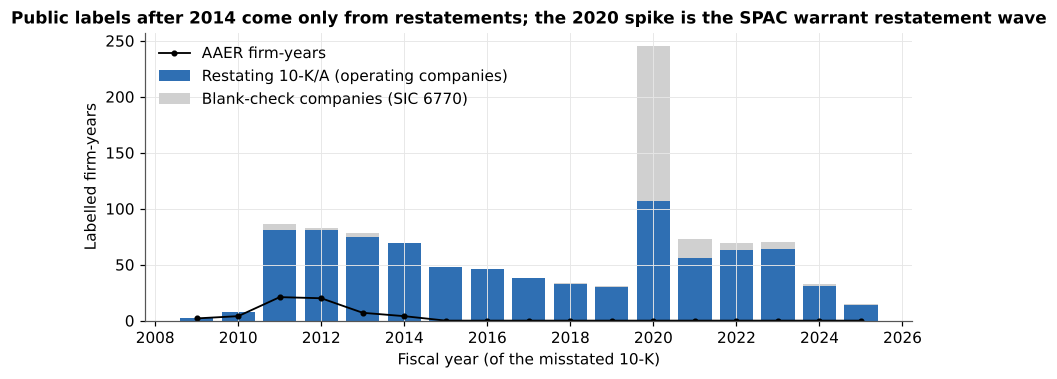

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(lab.index, lab.restated - lab.restated_spac, color=plots.ACCENT, label='Restating 10-K/A (operating companies)')
ax.bar(lab.index, lab.restated_spac, bottom=lab.restated - lab.restated_spac, color=plots.LIGHT, label='Blank-check companies (SIC 6770)')
ax.plot(lab.index, lab.aaer, color='black', marker='o', ms=3, lw=1.2, label='AAER firm-years')
ax.set_title('Public labels after 2014 come only from restatements; the 2020 spike is the SPAC warrant restatement wave')
ax.set_ylabel('Labelled firm-years'); ax.set_xlabel('Fiscal year (of the misstated 10-K)'); plots.years(ax); ax.legend(loc='upper left')
plots.save(fig, 'F04_obj3_labels_by_year'); plt.show()

## 4. Transfer test — Compustat-trained models on XBRL inputs (AAER labels, 2011–2014)
Models are trained on the Bao et al. Compustat data up to T−2 with serial AAERs recoded, using the 27 raw items available in both sources (share price is not in the FSDS), and scored on (a) Compustat firms and (b) XBRL firms in year T.

In [7]:
def transfer(models_=('LR', 'RUSBoost', 'XGB')):
    out = []
    for T in range(2011, 2015):
        tr = bao[bao.fyear <= T - GAP]
        tx, tc = P[P.fyear == T], bao[bao.fyear == T]
        aaers = set(tx.loc[tx.aaer == 1, 'p_aaer']) | set(tc.loc[tc.misstate == 1, 'p_aaer'].dropna())
        y = tr.misstate.values.copy(); y[tr.p_aaer.isin(aaers).values] = 0
        Xx = tx[data.RAW27].fillna(0)            # Compustat convention: unreported item = 0
        for m in models_:
            sx, mdl = models.fit_predict(m, data.RAW27, tr, y, Xx.assign(at=tx['at'].fillna(0)))
            sc, _ = models.fit_predict(m, data.RAW27, tr, y, tc)
            out.append(pd.DataFrame(dict(fyear=T, firm=tx.cik.values, y=tx.aaer.values, model=m, source='XBRL', score=sx)))
            out.append(pd.DataFrame(dict(fyear=T, firm=tc.gvkey.values, y=tc.misstate.values, model=m, source='Compustat', score=sc)))
    return pd.concat(out, ignore_index=True)

tp = models.cached(CACHE / 'obj3_transfer_predictions.parquet', transfer)
rows = []
for (src, m), g in tp.groupby(['source', 'model']):
    b = metrics.cluster_bootstrap(g.sort_values(['fyear', 'firm']), B=300)
    s = metrics.summarise(metrics.per_year(g, ['source', 'model']), ['source', 'model'], range(2011, 2015)).iloc[0]
    rows.append(dict(source=src, model=m, mean_auc=b['estimate'], lo=b['lo'], hi=b['hi'], pooled_auc=roc_auc_score(g.y, g.score),
                     positives=int(g.y.sum()), hits1=s.hits1, hits5=s.hits5))
tt = pd.DataFrame(rows); tt.to_csv(TABLES / 'T15_obj3_transfer.csv', index=False); tt.round(3)

,source,model,mean_auc,lo,hi,pooled_auc,positives,hits1,hits5
0,Compustat,LR,0.760,0.705,0.823,0.751,55,2,6
1,Compustat,RUSBoost,0.754,0.699,0.815,0.754,55,4,8
2,Compustat,XGB,0.723,0.658,0.790,0.736,55,3,7
3,XBRL,LR,0.717,0.646,0.771,0.675,52,0,3
4,XBRL,RUSBoost,0.686,0.596,0.779,0.653,52,4,5
5,XBRL,XGB,0.691,0.605,0.776,0.659,52,1,4


## 5. XBRL-native models with restatement labels, 2013–2024
* Sample: original 10-Ks, fiscal 2009–2025, excluding blank-check companies (SIC 6770) in the main specification.
* Inputs: 27 raw items (`xraw`) and 13 indicators computed from each filing and its comparative year (`xratio`: working-capital accruals, Δreceivables, Δinventory, soft assets, ΔROA, total accruals, issuance, RE/assets, EBIT/assets, sales growth, loss, leverage, size).
* **Label timing:** a training firm-year counts as restated only if the restating 10-K/A was filed by 31 December of the test year, i.e. before the test-year 10-K. Without this, the model would learn from restatements that were not yet public.
* Firm-level exclusion: training firm-years of companies that restate in the test year are dropped.

In [8]:
X = P[(P.spac == 0) & P.fyear.between(2009, 2025)].reset_index(drop=True)
XFS = {'xraw': data.RAW27, 'xratio': fsds.XRATIOS, 'xall': data.RAW27 + fsds.XRATIOS}
YRS = list(range(2013, 2025))
cfg = [('Size', 'xraw', 'firm_excl'), ('LR', 'xratio', 'firm_excl'), ('LR', 'xall', 'firm_excl'),
       ('RUSBoost', 'xall', 'firm_excl'), ('GBM', 'xall', 'firm_excl'), ('XGB', 'xall', 'firm_excl'), ('XGB', 'xraw', 'firm_excl')]
nat = models.cached(CACHE / 'obj3_xbrl_restatement_predictions.parquet', models.rolling, X, cfg, YRS, XFS,
                    y_col='restated', aaer_col='cik', firm_col='cik', seeds=(42, 7, 2024), label_date_col='filed_a', verbose=False)
nat['spec'] = nat.model + ' | ' + nat.fset
pyn = metrics.per_year(nat, ['spec', 'seed']); pyn.to_csv(TABLES / 'T16_obj3_native_by_year.csv', index=False)
sn = metrics.summarise(pyn, ['spec', 'seed'], YRS).groupby('spec').mean(numeric_only=True).sort_values('auc', ascending=False)
sn.to_csv(TABLES / 'T17_obj3_native_summary.csv')
sn[['auc', 'ap', 'ndcg1', 'hits1', 'hits5', 'pos', 'capture1', 'capture5', 'prec1', 'prec5']].round(4)

,auc,ap,ndcg1,hits1,hits5,pos,capture1,capture5,prec1,prec5
spec,,,,,,,,,,
GBM | xall,0.688,0.036,0.078,38.333,117.667,660.0,0.058,0.178,0.055,0.033
RUSBoost | xall,0.680,0.023,0.032,18.000,95.000,660.0,0.027,0.144,0.026,0.027
LR | xall,0.677,0.024,0.029,17.000,109.000,660.0,0.026,0.165,0.024,0.031
LR | xratio,0.676,0.021,0.031,20.000,86.000,660.0,0.030,0.130,0.029,0.024
XGB | xall,0.669,0.030,0.064,34.333,112.667,660.0,0.052,0.171,0.049,0.032
XGB | xraw,0.666,0.028,0.060,29.667,104.000,660.0,0.045,0.158,0.042,0.029
Size | xraw,0.344,0.007,0.004,3.000,6.000,660.0,0.004,0.009,0.004,0.002


In [9]:
# Robustness: (a) include blank-check companies, (b) ignore label timing (uses restatements not yet public)
Xs = P[P.fyear.between(2009, 2025)].reset_index(drop=True)
rob_a = models.cached(CACHE / 'obj3_rob_with_spac.parquet', models.rolling, Xs, [('XGB', 'xall', 'firm_excl')], YRS, XFS,
                      y_col='restated', aaer_col='cik', firm_col='cik', label_date_col='filed_a', verbose=False)
rob_b = models.cached(CACHE / 'obj3_rob_no_label_timing.parquet', models.rolling, X, [('XGB', 'xall', 'firm_excl')], YRS, XFS,
                      y_col='restated', aaer_col='cik', firm_col='cik', label_date_col=None, verbose=False)
main = nat[(nat.spec == 'XGB | xall') & (nat.seed == 42)]
rob = pd.DataFrame({k: metrics.summarise(metrics.per_year(v, ['model']), ['model'], YRS).iloc[0][['auc', 'ap', 'hits1', 'hits5', 'pos']]
                    for k, v in {'Main (no SPACs, label timing)': main, 'Including SPACs': rob_a, 'Ignoring label timing': rob_b}.items()}).T
rob.to_csv(TABLES / 'T18_obj3_robustness.csv'); rob

,auc,ap,hits1,hits5,pos
"Main (no SPACs, label timing)",0.674,0.03,31,112,660
Including SPACs,0.664,0.028,29,120,834
Ignoring label timing,0.674,0.032,34,114,660


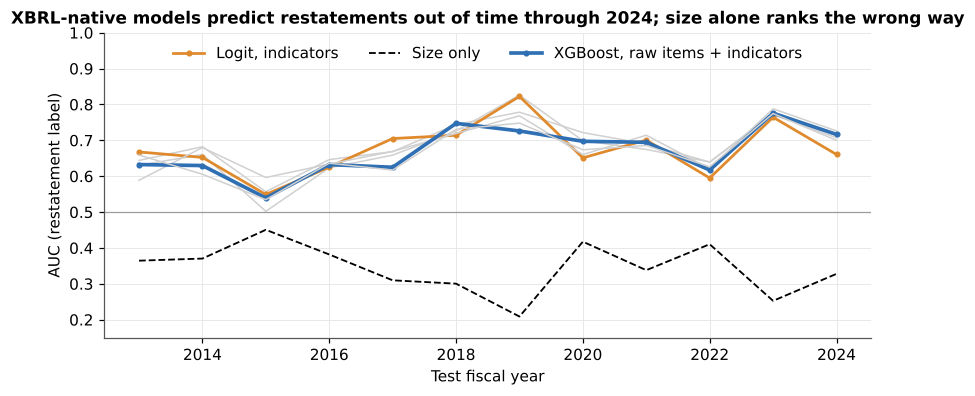

In [10]:
yy = pyn.groupby(['spec', 'fyear']).auc.mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 3.6))
for c in yy.columns:
    if c == 'XGB | xall': ax.plot(yy.index, yy[c], color=plots.ACCENT, lw=2.4, marker='o', ms=3, label='XGBoost, raw items + indicators')
    elif c == 'LR | xratio': ax.plot(yy.index, yy[c], color=plots.SERIES[1], lw=1.8, marker='o', ms=3, label='Logit, indicators')
    elif c == 'Size | xraw': ax.plot(yy.index, yy[c], color='black', lw=1.2, ls='--', label='Size only')
    else: ax.plot(yy.index, yy[c], color=plots.LIGHT, lw=1)
ax.axhline(0.5, color=plots.GREY, lw=0.8); ax.set_ylabel('AUC (restatement label)'); ax.set_xlabel('Test fiscal year'); plots.years(ax); ax.set_ylim(0.15, 1.0)
ax.set_title('XBRL-native models predict restatements out of time through 2024; size alone ranks the wrong way'); ax.legend(loc='upper center', ncol=3)
plots.save(fig, 'F05_obj3_native_auc_by_year'); plt.show()

## 6. Distribution shift between and within sources (PSI)

In [11]:
ref = bao[bao.fyear.between(2003, 2012)]
rows = []
for y in range(2011, 2026):
    g = P[P.fyear == y]
    for v in data.RAW27:
        rows.append(dict(fyear=y, item=v, psi_vs_compustat=metrics.psi(ref[v], g[v].fillna(0)),
                         psi_vs_xbrl_2011_12=metrics.psi(P.loc[P.fyear.between(2011, 2012), v].dropna(), g[v].dropna())))
D = pd.DataFrame(rows)
bench = np.median([metrics.psi(ref[v], bao.loc[bao.fyear == y, v]) for y in (2013, 2014) for v in data.RAW27])
D.to_csv(TABLES / 'T19_obj3_psi.csv', index=False)
summ = D.groupby('fyear').agg(items_psi_gt_0_25_vs_compustat=('psi_vs_compustat', lambda s: (s > 0.25).sum()),
                              items_psi_gt_0_5_vs_compustat=('psi_vs_compustat', lambda s: (s > 0.5).sum()),
                              median_psi_vs_compustat=('psi_vs_compustat', 'median'),
                              median_psi_within_xbrl=('psi_vs_xbrl_2011_12', 'median'))
print(f'Benchmark: median PSI of Compustat 2013-14 against Compustat 2003-12 = {bench:.3f}')
summ.round(3).T

Benchmark: median PSI of Compustat 2013-14 against Compustat 2003-12 = 0.026


fyear,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
items_psi_gt_0_25_vs_compustat,18.000,18.000,18.000,16.000,15.000,15.000,15.000,14.000,15.000,15.000,16.000,16.000,16.000,16.000,19.000
items_psi_gt_0_5_vs_compustat,11.000,11.000,11.000,10.000,9.000,9.000,9.000,9.000,8.000,8.000,9.000,8.000,8.000,9.000,9.000
median_psi_vs_compustat,0.380,0.349,0.331,0.315,0.299,0.298,0.313,0.287,0.276,0.277,0.341,0.272,0.281,0.334,0.391
median_psi_within_xbrl,0.001,0.001,0.004,0.013,0.019,0.028,0.043,0.054,0.063,0.074,0.085,0.097,0.120,0.158,0.161


## Findings for Objective 3

* All 70 FSDS quarters from 2009 Q2 to 2026 Q3 are usable after resolving duplicate downloads and inconsistent file suffixes; the panel covers fiscal 2009–2025.
* Core balance-sheet and income items map closely to Compustat; gross PP&E, other investments and COGS are poorly covered in XBRL, and share price is absent.
* AAER labels end with fiscal 2015 misstatements, so they support only a 2011–2014 transfer test, where Compustat-trained models lose discrimination on XBRL inputs, driven by measurement shift (PSI) rather than time.
* An XBRL-derived restatement label provides public outcome data through fiscal 2024 with known disclosure dates. XBRL-native models trained only on labels already public at prediction time predict restatements out of time across 2013–2024; see the summary table for values. Restatement is a broader and noisier construct than AAER enforcement, which the manuscript discusses.